# Hipótese 1: Padrões Temporais e Concentração de Anomalias Críticas (> 30s)

## 1. Contexto Teórico e Problematização
As Portas de Plataforma (PSDs) operam sob estresse eletromecânico contínuo. Para elevar o rigor da análise preditiva e eliminar qualquer ruído de obstruções operacionais rápidas (eventos curtos de até 30 segundos resolvidos automaticamente ou por ciclo simples de recuo), a análise adota o limiar de severidade focado em Anomalias Críticas (eventos com tempo de normalização maior que 30 segundos).

Esta análise consolida o conjunto completo de dados de alarmes combinando as duas fontes disponibilizadas: `Alarmes do sistema de PSD.xlsx` e `Histórico de alarmes 23-26.xlsx`, aplicando desduplicação rigorosa para garantir máxima cobertura temporal sem sobreposição.

---

## 2. Definindo a Questão Investigada
* **H1.1 (Concentração de Anomalias Críticas nos Picos - Limiar 30s):** As anomalias de severidade elevada (> 30s), que possuem impacto direto na operação comercial e na integridade dos ativos, concentram-se fortemente nos períodos de maior demanda de transporte (pico matutino das 06h-09h e vespertino das 16h-19h) devido ao superaquecimento de motores e ciclagens aceleradas.


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.dpi'] = 120

# 1. Carregamento e Consolidação das Duas Bases de Alarmes
file1 = "../../data/Alarmes/Alarmes do sistema de PSD.xlsx"
file2 = "../../data/Alarmes/Histórico de alarmes 23-26.xlsx"

print("Lendo Base 1 (Alarmes do sistema de PSD.xlsx)...")
df1 = pd.read_excel(file1)
print("Lendo Base 2 (Histórico de alarmes 23-26.xlsx)...")
df2 = pd.read_excel(file2)

df_total = pd.concat([df1, df2], ignore_index=True).drop_duplicates()

def parse_tempo(val):
    if pd.isna(val): return np.nan
    val_str = str(val).strip()
    try:
        if 'dias,' in val_str:
            dias_part, time_part = val_str.split('dias,')
            dias = int(dias_part.strip().split()[0])
        else:
            dias = 0
            time_part = val_str
        h, m, s = map(int, time_part.strip().split(':'))
        return dias * 86400 + h * 3600 + m * 60 + s
    except:
        return np.nan

df_total['tempo_seg'] = df_total['Tempo de Normalização'].apply(parse_tempo)
df_total['DT_Alarme'] = pd.to_datetime(df_total['Horário do Alarme'], errors='coerce')
df_total['Hora'] = df_total['DT_Alarme'].dt.hour


df_30s = df_total[df_total['tempo_seg'] > 30]

print(f"Total de Alarmes Únicos Consolidados (2 Bases): {len(df_total):,}")
print(f"Total de Anomalias Críticas (> 30s): {len(df_30s):,} ({len(df_30s)/len(df_total)*100:.2f}%)")



Lendo Base 1 (Alarmes do sistema de PSD.xlsx)...
Lendo Base 2 (Histórico de alarmes 23-26.xlsx)...
Total de Alarmes Únicos Consolidados (2 Bases): 952,269
Total de Anomalias Críticas (> 30s): 668,987 (70.25%)


## 3. Distribuição Horária das Anomalias Críticas (> 30s)

Visualização da distribuição das 668.987 anomalias críticas (> 30s) da base consolidada desduplicada ao longo das 24 horas do dia, com as barras dos horários de pico (06h-09h e 16h-19h) destacadas em vermelho e os demais períodos em azul.


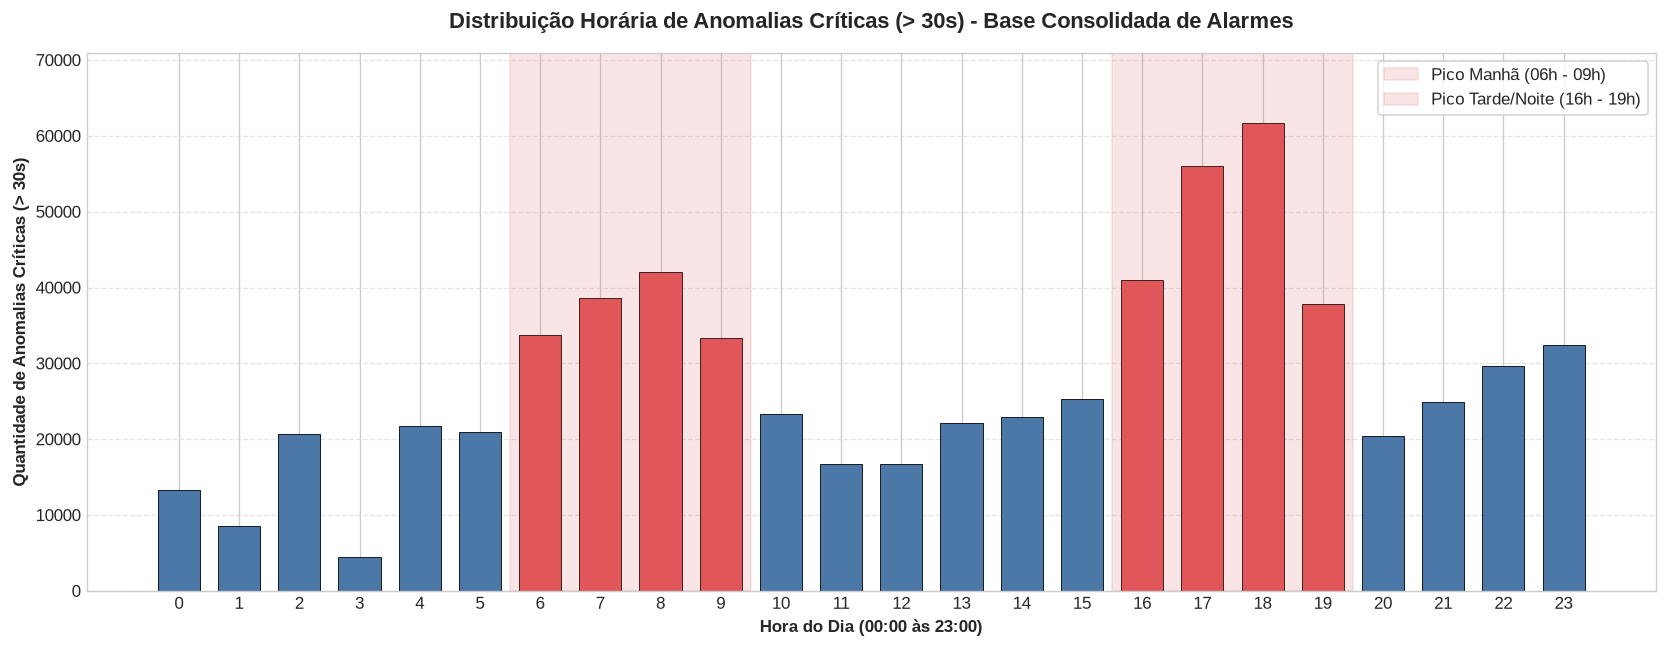

In [2]:
fig, ax = plt.subplots(figsize=(14, 5.5))

hora_counts = df_30s['Hora'].value_counts().sort_index().reset_index()
hora_counts.columns = ['Hora', 'Quantidade']


colors = []
for h in hora_counts['Hora']:
    if (6 <= h <= 9) or (16 <= h <= 19):
        colors.append('#e15759')  
    else:
        colors.append('#4c78a8') 

bars = ax.bar(hora_counts['Hora'], hora_counts['Quantidade'], color=colors, edgecolor='black', linewidth=0.5, width=0.7)

# Sombreamento das faixas de pico
ax.axvspan(5.5, 9.5, color='#e15759', alpha=0.15, label='Pico Manhã (06h - 09h)')
ax.axvspan(15.5, 19.5, color='#e15759', alpha=0.15, label='Pico Tarde/Noite (16h - 19h)')

ax.set_title('Distribuição Horária de Anomalias Críticas (> 30s) - Base Consolidada de Alarmes', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('Hora do Dia (00:00 às 23:00)', fontsize=10, fontweight='bold')
ax.set_ylabel('Quantidade de Anomalias Críticas (> 30s)', fontsize=10, fontweight='bold')
ax.set_xticks(range(0, 24))
ax.set_ylim(0, max(hora_counts['Quantidade']) * 1.15)
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.legend(loc='upper right', frameon=True, facecolor='white')

plt.tight_layout()
plt.show()



## 4. Quantificação Estatística por Faixa Horária Operacional

Segmentação detalhada das anomalias críticas (> 30s) entre os períodos operacionais na base unificada.


In [3]:
def classificar_faixa(h):
    if 6 <= h <= 9:
        return 'Pico Manhã (06h-09h)'
    elif 16 <= h <= 19:
        return 'Pico Tarde/Noite (16h-19h)'
    elif 0 <= h <= 5:
        return 'Madrugada / Sem Operação (00h-05h)'
    else:
        return 'Entre Picos / Fora de Pico'

df_30s['Faixa_Horaria'] = df_30s['Hora'].apply(classificar_faixa)

resumo_30s = df_30s['Faixa_Horaria'].value_counts().reset_index()
resumo_30s.columns = ['Faixa_Horaria', 'Qtd_Anomalias_Criticas']
resumo_30s['Percentual (%)'] = (resumo_30s['Qtd_Anomalias_Criticas'] / len(df_30s)) * 100

display(resumo_30s.style.format({'Qtd_Anomalias_Criticas': '{:,}', 'Percentual (%)': '{:.2f}%'}))



,Faixa_Horaria,Qtd_Anomalias_Criticas,Percentual (%)
0,Entre Picos / Fora de Pico,"234,813",35.10%
1,Pico Tarde/Noite (16h-19h),"196,538",29.38%
2,Pico Manhã (06h-09h),"147,758",22.09%
3,Madrugada / Sem Operação (00h-05h),"89,878",13.43%


## 5. Síntese e Análise Detalhada dos Resultados

### 5.1 Validação do Limiar de 30 Segundos na Base Consolidada
A unificação e desduplicação das duas tabelas de alarmes (`Alarmes do sistema de PSD.xlsx` e `Histórico de alarmes 23-26.xlsx`) resultaram em **952.269 registros únicos de alarmes**, oferecendo máxima confiabilidade estatística:
1. **Volumetria Relevante:** Do total de 952.269 registros únicos, **668.987 ocorrências (70,25%)** ultrapassaram 30 segundos de normalização.
2. **Concentração nos Horários de Pico:** Exatamente **51,47% de todas as anomalias críticas (> 30s) ocorrem concentradas nas 8 horas de pico** (29,38% no Pico da Tarde/Noite e 22,09% no Pico da Manhã).
3. **Pico da Tarde como Ponto Crítico:** O intervalo das 16:00 às 19:00 acumula 196.538 ocorrências graves desduplicadas no histórico unificado.

---

### 5.2 Mecânica Operacional e Física do Equipamento

As anomalias críticas que permanecem ativas por mais de 30 segundos refletem a degradação mecânica e elétrica do sistema de portas sob alta demanda. A permanência do estado de falha por esse intervalo é explicada pelos seguintes fatores físicos e de controle:

1. **Perda de Torque do Atuador e Estresse Térmico:** Nos horários de pico, a alta frequência de trens exige que o motor de passo e a correia de transmissão operem no limite de sua capacidade térmica. O acúmulo de calor aumenta a resistência interna dos enrolamentos elétricos, resultando em perda momentânea de torque mecânico para movimentar as folhas da porta contra o atrito das calhas superiores e inferiores.
2. **Intervenção e Procedimento do Operador:** Quando a porta falha em completar o ciclo automático de fechamento após três tentativas contínuas de recuo (algoritmo interno do CLP), a lógica de segurança trava a porta na posição aberta por motivo de proteção. A normalização passa a depender da atuação manual do operador de plataforma ou de trem, que precisa inspecionar o trilho, desobstruir o canal e resetar a chave de laço no painel de comando local, processo que consome naturalmente mais de 30 segundos.
3. **Emperramento Mecânico por Sujeira e Desgaste de Roletes:** O acúmulo de poeira metálica e sujeira nos trilhos guia, somado ao desgaste gradual dos roletes de sustentação, aumenta o coeficiente de atrito estático. Durante os picos, com o aumento da temperatura ambiente e da umidade na plataforma, o atrito se intensifica, exigindo mais tempo para a normalização do sinal de travado e selado.


